In [2]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import random as rd
%matplotlib ipympl


Préliminaires

In [3]:
a = np.array([1, 2, 3])
print(np.shape(a[:,None]))
print(np.shape(a[None,:]))
print(a[:, None] - a[None, :])


(3, 1)
(1, 3)
[[ 0 -1 -2]
 [ 1  0 -1]
 [ 2  1  0]]


1. a[:,None] est de forme (3,1)
a[None,:] est de forme (1,3)
2. a[:, None] - a[None, :] est de forme (3,3). l'élément [i,j] de la matrice est i-j.
3. b[:, None, :] - b[:, :, None] sera de forme (2,3,3)

Initialisation

In [4]:
# les bornes pour le tirage au sort initial
mass_max = 3.
mass_min= 0.01
x_min, x_max = -10., 10.
y_min, y_max = -10., 10.

speed_max = 1.


In [5]:

# votre code

def init_problem(N):
    """
    retourne un tuple masses, positions, speeds
    de formes resp.   (N,)    (2, N)     (2, N)
    tiré au sort dans les bornes définies ci-dessus
    """
    masse=np.random.uniform(mass_min,mass_max,(N,)) #fabrication d'un tableau de masses aléatoires
    positions=np.random.uniform(np.array([x_min,y_min])[:,None],np.array([x_max,y_max])[:,None],(2,N)) #fabrication du tableau des positions
    #On lui fournit deux tableaux qu'on reshape afin que np.random.uniform saisisse les bornes correctement.
    speeds=np.random.uniform(0.,speed_max,(2,N))#Fabrication du tableau des vitesses, comme précédement pour les masses.
    return masse,positions,speeds


In [6]:


# pour tester

# normalement vous devez pouvoir faire ceci

masses, positions, speeds = init_problem(10)

# et ceci devrait afficher OK
try:
    assert masses.shape == (10,) and positions.shape == speeds.shape == (2, 10)
    print("OK")
except:
    print("KO")
#C'est OK

OK


In [7]:
# for your convenience

def init3():
    # first element is sun-like: heavy, at the center, and no speed
    masses = np.array([3, 1, 1], dtype=float)
    positions = np.array([
        [0, 5, -5], 
        [0, 1, -1]], dtype=float)
    speeds = np.array([
        [0, -1, 1], 
        [0, 0, 0]], dtype=float)
    return masses, positions, speeds


Les forces

In [8]:


# votre code
def forces(masses, positions, G=1.0):
    """
    returns an array of shape (2,  N)
    that contains the force felt by each mass from all the others
    G is the Newton constant and by default is set to 1 
    (we have abstract units anyway)
    """
    diff=positions[:,:,None]-positions[:,None,:]
    #Je calcule les différences r_i-r_j, pour fabriquer les vecteurs différences.
    #On broadcast sur les dimensions 2 dernières dimensions.

    distances=np.linalg.norm(diff,2,0)
    #A partir des vecteurs distances entre deux points, on calcule les distances en norme
    #entre chaque point

    np.fill_diagonal(distances,1.)
    #Ici on remplace les 0 de la diagonale par des 1 pour ne pas diviser par 0.
    #Remarquons qu'il n'est pas nécesaire de faire davantage d'opérations pour que 
    #la masse i n'agisse pas sur la masse i, puisque le vecteur différence r_i-r_i
    #est d'ors et déjà nul dans le tableau diff.

    masseij=masses[:,None]*masses[None,:] #Construction du tableau de produits des masses.

    forcij=(G*distances**(-3)*masseij)
    #On construit le tableau des préfacteurs (i,j) de dimension 1
    forcij=diff*forcij
    #multiplication des vecteurs par les préfacteurs
    forcij=np.sum(forcij,1)
    #On effectue la somme sur l'axe 1, qui correspond aux colonnes et à l'indice j.
    return forcij

    


In [9]:


# pour tester, voici les valeurs attendues avec la config prédéfinie

masses, positions, speeds = init3()

f = forces(masses, positions)
print(f)
# should be true
np.all(np.isclose(f, np.array([[ 0. , -0.12257258,  0.12257258],[ 0.        , -0.02451452,  0.02451452]])))


[[ 0.         -0.12257258  0.12257258]
 [ 0.         -0.02451452  0.02451452]]


np.True_

Le simulateur

In [10]:

# votre code

def simulate(masses, positions, speeds, dt=0.1, nb_steps=100):
    """
    should return the positions across time
    so an array of shape (nb_steps, 2, N)
    optional dt is the time step
    """
    dim,N=np.shape(positions)
    #On récupère dim et N dans positions
    stock=np.zeros((nb_steps,dim,N))
    #Allocation de l'espace
    stock[0,:,:]=positions
    #Initialisation des positions
    vitesse_courante=speeds
    #initialisation des vitesses courantes
    for i in range(nb_steps-1):
        #boucle du temps
        position_courante=stock[i,:,:]
        #On récupère la position courante
        forces_courantes=forces(masses,position_courante)
        #Calcul des forces courantes
        acc_courante=forces_courantes/masses
        #calcul des accélérations liées aux forces
        vitesse_courante=vitesse_courante+acc_courante*dt
        #On calcule les nouvelles vitesses
        stock[i+1,:,:]=position_courante+vitesse_courante*dt
        #On met à jour les positions suivantes dans l'espace de travail.
    return stock


In [11]:


# pour tester

SMALL_STEPS = 4

s = simulate(masses, positions, speeds, nb_steps=SMALL_STEPS)

try:
    if s.shape == (SMALL_STEPS, 2, 3):
        print("shape OK")
except Exception as exc:
    print(f"OOPS {type(exc)} {exc}")


shape OK


In [12]:


# pour tester: should be true

# first step
positions1 = s[1]

np.all(np.isclose(positions1, np.array([ [ 0.        ,  4.89877427, -4.89877427],    [ 0.        ,  0.99975485, -0.99975485] ])))


np.True_

In [80]:

# votre code

def draw(simulation, masses, colors=None, scale=10.):
    """
    takes as input the result of simulate() above,
    and draws the nb_steps positions of each of the N bodies
    ideally it should return a matplotlib Axes object

    one can provide a collection of N colors to use for each body
    if not provided this is randomized

    also the optional scale parameter is used as a constant
    multiplier to obtain the final size of each dot on the figure
    """
    for i in range(len(masses)):
    #Je n'ai pas compris comment utiliser l'appel avec l'étoile de type f(*t). 
    #C'est donc après moult essais, que j'ai dpu m'en remettre à une boucle for pour
    #dessiner chaque masse de façon séparée. D'où cette boucle sur les masses.
        if colors is None:
            #Ce test a pour simple but d'éviter les écueils d'appeler None[i] si 
            #aucune couleur n'est fournie à notre fonction
            plt.scatter(simulation[:,0,i],simulation[:,1,i],s=scale*masses[i])
        else:
            plt.scatter(simulation[:,0,i],simulation[:,1,i],color=colors[i],s=scale*masses[i])
        #simulation[:,0,i] désigne pour la masse i la liste des positions en x
        #simulation[:,1,i] désigne pour la masse i la liste des positions en y
        #colors[i] désigne la couleur à donner à la masse i, et scale*masses[i] 
        #pondère la taille du point à donner aux points représentant la masse i.
    plt.show()
    #On montre ensuite le dessin effectué.


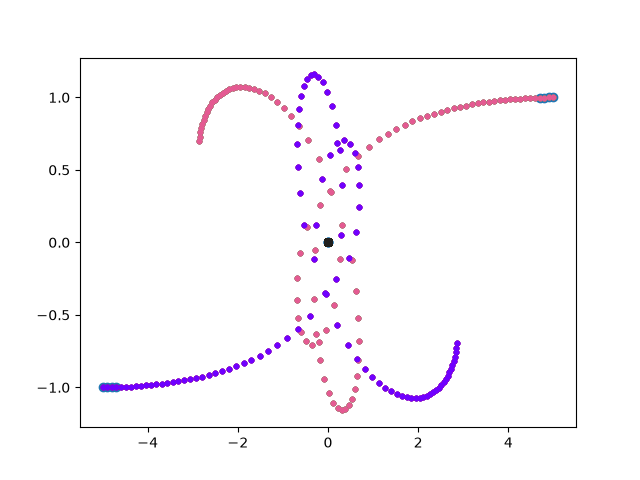

In [81]:
colors3 = np.array([[32, 32, 32],(228, 90, 146),(111, 0, 255),]) / 255


# décommentez ceci pour tester votre code

masses, positions, speeds = init3()
draw(simulate(masses, positions, speeds), masses, colors3)


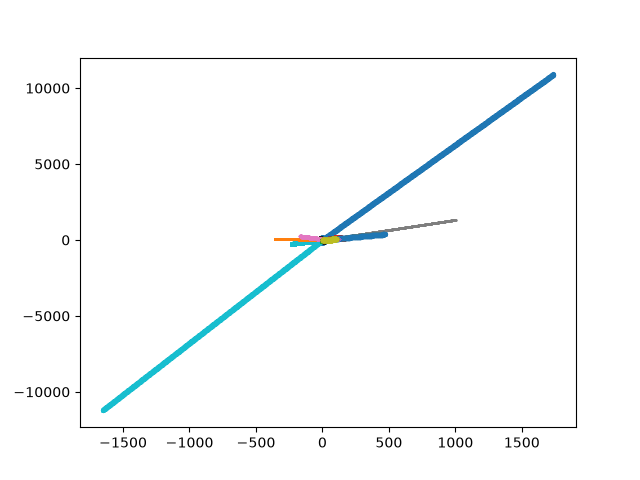

In [86]:
m5, p5, s5 = init_problem(5)
sim5 = simulate(m5, p5, s5, nb_steps=1000)
draw(sim5, m5, scale=3);
plt.savefig("random5.png")

